<a href="https://colab.research.google.com/github/emilytiari/Python/blob/main/C%C3%B3pia_de_Tratamento_com_Spark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importar biblioteca pandas
import pandas as pd

# Exibe todas as colunas, se necessário, sem cortar a visialização
pd.set_option("display.max_columns", None)

# Exibe mais largura na tela para facilitar a leitura das tabelas
pd.set_option("display.width",100)


In [ ]:
df = pd.read_csv("/content/dataset_aula5_intermediario - dataset_aula5_intermediario.csv")

df.head(10)

,id,temperatura,tempo_ciclo,producao,status
0,1,61.31,36.52,144.0,MANUTENCAO
1,2,77.98,36.7,171.0,OK
2,3,72.26,26.53,70.0,ok
3,4,57.95,23.74,110.0,ok
4,5,65.37,NaN,76.0,PARADA
5,6,83.21,36.01,151.0,OK
6,7,50.59,NaN,191.0,ok
7,8,66.57,31.82,150.0,ok
8,9,80.13,43.26,56.0,ok
9,10,63.07,34.14,125.0,OK


In [ ]:
# Mostrar a aquantidade de linhas e colunas
df.shape

(160, 5)

In [ ]:
# Exibe o tipo de cada coluna
df.dtypes

,0
id,int64
temperatura,float64
tempo_ciclo,object
producao,float64
status,object


# Resumo geral da base


*  Info()
ajuda a entender a quantidade de valores nulos

tipos das colunas

estrutura geral do Dataframe


In [ ]:
# Mostra um resumo técnico dp DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           160 non-null    int64  
 1   temperatura  145 non-null    float64
 2   tempo_ciclo  144 non-null    object 
 3   producao     155 non-null    float64
 4   status       160 non-null    object 
dtypes: float64(2), int64(1), object(2)
memory usage: 6.4+ KB


In [ ]:
# Verificar quantos valores faltantes existem em cada coluna
df.isnull().sum()

,0
id,0
temperatura,15
tempo_ciclo,16
producao,5
status,0


# Identificando valores duplicados

In [ ]:
#Conta quantas linhas duplicadas existem na base
df.duplicated().sum()

np.int64(6)

In [ ]:
# Mostrar linhas que possuem pelo menos um valor ausente
df[df.isnull().any(axis=1)].head()

,id,temperatura,tempo_ciclo,producao,status
4,5,65.37,NaN,76.0,PARADA
6,7,50.59,NaN,191.0,ok
13,14,NaN,39.23,78.0,ok
34,35,77.42,NaN,163.0,MANUTENCAO
41,42,NaN,NaN,160.0,ok


# Explicação
*   df.isnull() verifica ausências
*   .any(axis=1) Pergunta: existe pelo menos uma ausência na linha?
*   df[...]usa condição de filtro






In [ ]:
# Criar cópia da base original
df_tratado = df.copy()

df_tratado.head()

,id,temperatura,tempo_ciclo,producao,status
0,1,61.31,36.52,144.0,MANUTENCAO
1,2,77.98,36.7,171.0,OK
2,3,72.26,26.53,70.0,ok
3,4,57.95,23.74,110.0,ok
4,5,65.37,NaN,76.0,PARADA


Removendo duplicados

In [ ]:
df_tratado = df_tratado.drop_duplicates()

df_tratado.shape

(154, 5)

In [ ]:
# Verificando se existem valores duplicados ainda

df_tratado.duplicated().sum()

np.int64(0)

In [ ]:
# Conversão de dados tempo_ciclo em números

df_tratado['tempo_ciclo'] = pd.to_numeric(df_tratado["tempo_ciclo"], errors="coerce")

df_tratado.dtypes

,0
id,int64
temperatura,float64
tempo_ciclo,float64
producao,float64
status,object


In [ ]:
df_tratado.dtypes

,0
id,int64
temperatura,float64
tempo_ciclo,float64
producao,float64
status,object


:

# Preencher valores ausentes nas colunas temperatura, tempo ciclo e produção, com a média da própria coluna

In [ ]:
# Preencher valores ausentes da coluna de temperatura
df_tratado['temperatura'] = df_tratado['temperatura'].fillna(
    df_tratado['temperatura'].mean()
)

In [ ]:
# Preencher valores ausentes da coluna tempo_ciclo
df_tratado['tempo_ciclo'] = df_tratado['tempo_ciclo'].fillna(
    df_tratado['tempo_ciclo'].mean()
)

In [ ]:
#Preencher valores ausentes da coluna produção
df_tratado['producao'] = df_tratado['producao'].fillna(
    df_tratado['producao'].mean()
)

In [ ]:
df_tratado.head()

,id,temperatura,tempo_ciclo,producao,status
0,1,61.31,36.520000,144.0,MANUTENCAO
1,2,77.98,36.700000,171.0,OK
2,3,72.26,26.530000,70.0,ok
3,4,57.95,23.740000,110.0,ok
4,5,65.37,34.115308,76.0,PARADA


In [ ]:
# Convertendo todos os textos da coluna status para letras maiúsculas

df_tratado['status'] = df_tratado['status'].str.upper()

#Mostra os valores unicos na coluna
df_tratado['status'].unique()

array(['MANUTENCAO', 'OK', 'PARADA'], dtype=object)

#Verificando novamete valores duplicados

In [ ]:
#Verifica ausência após o tratamento
print('Valores faltantes por coluna:')
print(df_tratado.isnull().sum())

print('\nDuplicatas restantes: ')
print(df_tratado.duplicated().sum())

Valores faltantes por coluna:
id             0
temperatura    0
tempo_ciclo    0
producao       0
status         0
dtype: int64

Duplicatas restantes: 
0


In [ ]:
df_tratado.to_csv('dataset_tratado.csv', index=False)

print('Arquivo salvo com sucesso')

Arquivo salvo com sucesso


#Instalação do PySpark no Colab

In [ ]:
# Instalar PySpark no ambiente do notebook

!pip install pyspark -q

# Criando uma seção Spark

In [ ]:
# Importando a classe SparkSession
from pyspark.sql import SparkSession

#Criar a sessão Spark
spark = SparkSession.builder.appName('dados_tratados').getOrCreate()

spark

*   from pyspark.sql: indica qual modelo estamos importando
*   import SparkSession: disponibiliza essa classe no nosso código

*   SparkSession: Classe responsável pela sessão do Spark
*   builder: Permite a configuração antes de inicia-lá
*   appName:("Dados tratados"): Define o nome da aplicação como "dados tratados"
*   .getOrCreate(): Obtem uma sessão existente ou cria uma, caso não exista
*   spark: Guarda a referência da sessão na variável:`spark`


In [ ]:
#Lendo os dados com spark
spark_df = spark.read.csv("/content/dataset_aula5_intermediario - dataset_aula5_intermediario.csv",header=True, inferSchema=True)

# Mostrando os dados
spark_df.show(10)

+---+-----------+-----------+--------+----------+
| id|temperatura|tempo_ciclo|producao|    status|
+---+-----------+-----------+--------+----------+
|  1|      61.31|      36.52|   144.0|MANUTENCAO|
|  2|      77.98|       36.7|   171.0|        OK|
|  3|      72.26|      26.53|    70.0|        ok|
|  4|      57.95|      23.74|   110.0|        ok|
|  5|      65.37|       NULL|    76.0|    PARADA|
|  6|      83.21|      36.01|   151.0|        OK|
|  7|      50.59|       NULL|   191.0|        ok|
|  8|      66.57|      31.82|   150.0|        ok|
|  9|      80.13|      43.26|    56.0|        ok|
| 10|      63.07|      34.14|   125.0|        OK|
+---+-----------+-----------+--------+----------+
only showing top 10 rows


*   header = True: indica que a primeira linha contem nomes de colunas
*   inferSchema=True: True: pede para o Spark tentar identificar os tipos automaticamente







In [ ]:
# Mostrar o esquema base do spark

spark_df.printSchema()

root
 |-- id: integer (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- tempo_ciclo: string (nullable = true)
 |-- producao: double (nullable = true)
 |-- status: string (nullable = true)



In [ ]:
# Remover as duplicadas no DataFrame do Spark
spark_df_sem_dup = spark_df.drop_duplicates()

spark_df_sem_dup.show(5)

+---+-----------+-----------+--------+----------+
| id|temperatura|tempo_ciclo|producao|    status|
+---+-----------+-----------+--------+----------+
|106|      200.0|      34.52|    53.0|MANUTENCAO|
|  3|      72.26|      26.53|    70.0|        ok|
| 47|      89.14|      33.38|    70.0|        OK|
| 41|      63.56|      36.06|    70.0|        OK|
|148|      82.36|      37.49|    53.0|    PARADA|
+---+-----------+-----------+--------+----------+
only showing top 5 rows


In [ ]:
# Importar a função col para referenciar colunas no spark
from pyspark.sql.functions import col

# Converte a coluna tempo_ciclo para double
spark_df_convertido = spark_df_sem_dup.withColumn(
    "tempo_ciclo", col("tempo_ciclo").cast("double")
)

# Mostrando o esquema atualizado
spark_df_convertido.printSchema()

root
 |-- id: integer (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- tempo_ciclo: double (nullable = true)
 |-- producao: double (nullable = true)
 |-- status: string (nullable = true)



# Visualização de dados

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliotecas importadas com sucesso")

Bibliotecas importadas com sucesso


In [ ]:
base_tratada = pd.read_csv("/content/dataset_tratado.csv")

base_tratada

,id,temperatura,tempo_ciclo,producao,status
0,1,61.31,36.520000,144.0,MANUTENCAO
1,2,77.98,36.700000,171.0,OK
2,3,72.26,26.530000,70.0,OK
3,4,57.95,23.740000,110.0,OK
4,5,65.37,34.115308,76.0,PARADA
...,...,...,...,...,...
149,150,71.15,39.920000,58.0,PARADA
150,24,200.00,35.440000,72.0,OK
151,105,69.80,34.115308,159.0,OK
152,130,65.49,31.000000,93.0,OK


In [ ]:
# Definir estilo dos gráficos que serão apresentados

sns.set_theme(style="whitegrid",palette="colorblind")
print("Linhas e colunas",base_tratada.shape)
display(base_tratada.head(10))

Linhas e colunas (154, 5)


,id,temperatura,tempo_ciclo,producao,status
0,1,61.31,36.520000,144.0,MANUTENCAO
1,2,77.98,36.700000,171.0,OK
2,3,72.26,26.530000,70.0,OK
3,4,57.95,23.740000,110.0,OK
4,5,65.37,34.115308,76.0,PARADA
5,6,83.21,36.010000,151.0,OK
6,7,50.59,34.115308,191.0,OK
7,8,66.57,31.820000,150.0,OK
8,9,80.13,43.260000,56.0,OK
9,10,63.07,34.140000,125.0,OK


In [ ]:
print("valores faltantes: ")
print(base_tratada.isnull().sum())
print("linhas inteiramente duplicadas:", base_tratada.duplicated().sum)
print("repetições de id após a primeira ocorrência:", base_tratada["id"].duplicated().sum())
display(base_tratada[["temperatura", "tempo_ciclo","producao"]].describe())

valores faltantes: 
id             0
temperatura    0
tempo_ciclo    0
producao       0
status         0
dtype: int64
linhas inteiramente duplicadas: <bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
149    False
150    False
151    False
152    False
153    False
Length: 154, dtype: bool>
repetições de id após a primeira ocorrência: 4


,temperatura,tempo_ciclo,producao
count,154.000000,154.000000,154.000000
mean,75.168561,34.115308,124.637584
std,24.392333,5.243602,42.975782
min,47.610000,15.610000,50.000000
25%,64.652500,31.432500,83.000000
50%,72.540000,34.115308,129.500000
75%,76.490000,36.695000,159.750000
max,200.000000,52.750000,199.000000


In [ ]:
contagem_status = base_tratada.groupby("status").size().sort_values(ascending=False)
display(contagem_status)

,0
status,
OK,73
PARADA,56
MANUTENCAO,25


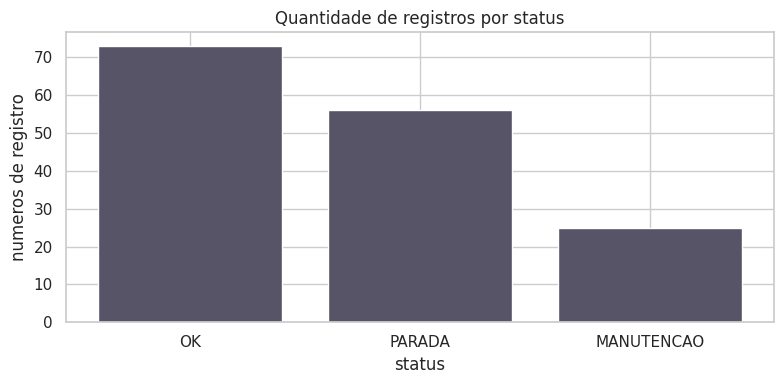

In [ ]:
# Primeiro gráfico com matplotlib
plt.figure(figsize=(8,4))
plt.bar(contagem_status.index,contagem_status.values, color="#565466")
plt.title("Quantidade de registros por status")
plt.xlabel("Status")
plt.ylabel("numeros de registro")
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()


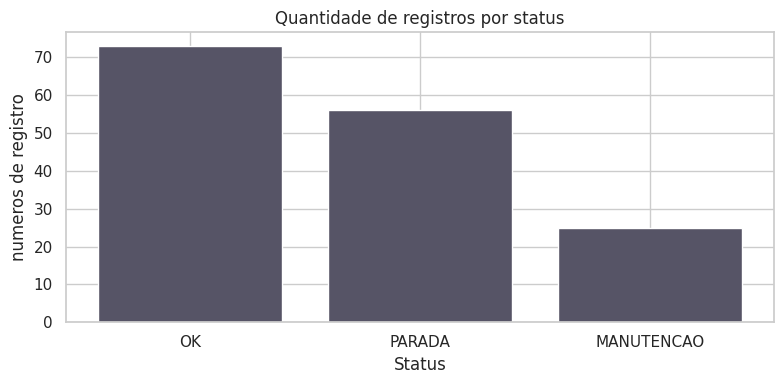

In [ ]:
# Primeiro gráfico com matplotlib

plt.figure(figsize=(8,4))
plt.bar(contagem_status.index,contagem_status.values, color="#565466")
plt.title("Quantidade de registros por status")
plt.xlabel("Status")
plt.ylabel("numeros de registro")
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()


,status,temperatura,tempo_ciclo,producao
0,MANUTENCAO,76.43,33.33,137.25
1,OK,74.95,33.64,118.20
2,PARADA,74.89,35.08,127.40


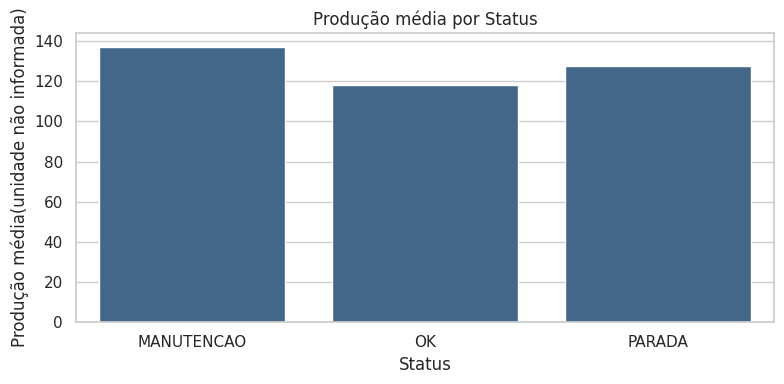

In [ ]:
# Agrupar e comparar as médias
medias_status = base_tratada.groupby("status")[["temperatura","tempo_ciclo","producao"]].mean().reset_index()
display(medias_status.round(2))

# Criação do Gráfico
plt.figure(figsize=(8,4))

sns.barplot(data=medias_status,
            x="status",
            y="producao",
            color="#376795",
            errorbar=None)

plt.title("Produção média por Status")
plt.xlabel("Status")
plt.ylabel("Produção média(unidade não informada)")
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(9,4))
sns.histplot(data=base_tratada,
             x="temperatura",
             bins=15,
             color="376795")
plt.title("Distribuição da temperatura")
plt.xlabel("Temperatura")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined